<a href="https://colab.research.google.com/github/VizDataWorks/eCommerce_data_analysis/blob/main/ecommerce-challenge/notebooks/05_best_customer_base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/VizDataWorks/CapitalOne_DataAnalysis/blob/main/ecommerce-challenge/notebooks/05_best_customer_base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 · Our best customer base, and KPIs to grow it

**Question:** Where is our best customer base, and what KPIs should the company track to acquire more customers there?

**Short answer:** **Tech Enthusiasts.** They're 12.6% of customers but 30.8% of profit: \$404 per customer against \$120–150 for every other segment, because they buy electronics. Most are in the West (Oregon, Nevada, California, Washington); the most valuable per customer are in the East (New Jersey, Georgia). Key KPIs: acquisition cost under about \$135, activation rate, and electronics in-stock rate.

**Approach**
- **Value = profit per customer over 2024–2025**, using the same order rules as notebooks 03 and 04. Delivered orders only.
- **Every customer counts**, including those with no orders (\$0), so averages show what a typical customer is worth.
- Orders from buyers not in the customer table are left out (no segment or location).

## 1. Setup

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Get the project data from GitHub: no Google Drive or sign-in needed
REPO = "https://github.com/VizDataWorks/CapitalOne_DataAnalysis.git"
!rm -rf repo
!git clone -q --depth 1 {REPO} repo
CLEAN = os.path.join("repo", "ecommerce-challenge", "data", "clean")

# Business rules from the brief
REFERRAL_DISCOUNT = 0.10
BLACK_FRIDAY_DISCOUNT = 0.20
BLACK_FRIDAYS = pd.to_datetime(["2024-11-29", "2025-11-28"])
CARRIER_FEE = 4.99


def shipping_charged(item_total):
    # $7.99 under $50, $4.99 from $50 to $99.99, free from $100
    return np.select([item_total < 50, item_total < 100], [7.99, 4.99], 0.0)

## 2. Load data

In [ ]:
customers = pd.read_csv(os.path.join(CLEAN, "customers.csv"),
                        usecols=["buyer_id", "customer_segment", "region", "state", "is_referred"],
                        dtype={"is_referred": "Int64"})
products = pd.read_csv(os.path.join(CLEAN, "products.csv"),
                       usecols=["sku_id", "category_name", "price", "profit_margin",
                                "currently_active_vendor", "active_product", "current_stock"])
sales = pd.read_csv(os.path.join(CLEAN, "sales.csv.gz"),
                    usecols=["order_id", "buyer_id", "sku_id", "quantity", "order_datetime", "is_revenue"],
                    parse_dates=["order_datetime"])



```
`# This is formatted as code`
```

## 3. Profit per customer

Same order rules as notebooks 03 and 04.

In [ ]:
lines = sales[sales.is_revenue & sales.quantity.notna()].merge(products, on="sku_id", how="left")
assert lines.price.notna().all(), "some sales lines have no matching product"
lines["list_revenue"] = lines.quantity * lines.price
lines["item_profit"] = lines.list_revenue * lines.profit_margin

orders = (lines.groupby("order_id")
               .agg(buyer_id=("buyer_id", "first"), order_time=("order_datetime", "min"),
                    list_revenue=("list_revenue", "sum"), item_profit=("item_profit", "sum"))
               .reset_index())

# Black Friday first: 20% off, by the buyer's local date
bf_discount = orders.list_revenue.where(orders.order_time.dt.normalize().isin(BLACK_FRIDAYS), 0) * BLACK_FRIDAY_DISCOUNT
pre_referral = orders.list_revenue - bf_discount

# Then 10% off a referred buyer's first delivered order
first_orders = (orders.dropna(subset=["buyer_id", "order_time"])
                      .sort_values(["order_time", "order_id"])
                      .drop_duplicates("buyer_id").order_id)
is_referred = orders.buyer_id.map(customers.set_index("buyer_id").is_referred).eq(1).fillna(False)
referral_discount = pre_referral.where(orders.order_id.isin(first_orders) & is_referred, 0) * REFERRAL_DISCOUNT

orders["item_revenue"] = pre_referral - referral_discount
orders["profit"] = (orders.item_profit - bf_discount - referral_discount
                    + shipping_charged(orders.item_revenue) - CARRIER_FEE)

In [ ]:
# One row per customer; customers with no orders count as 0
per_buyer = orders.groupby("buyer_id").agg(orders=("order_id", "size"), profit=("profit", "sum"))
cust = customers.join(per_buyer, on="buyer_id").fillna({"orders": 0, "profit": 0})
cust["is_active"] = cust.orders > 0
print(f"{len(cust):,} customers, ${cust.profit.sum():,.0f} profit in 2024–2025")

47,500 customers, $7,859,163 profit in 2024–2025


[link text](https://)## 4. Who: the most valuable segment

1.   List item
2.   List item



In [ ]:
lines["segment"] = lines.buyer_id.map(customers.set_index("buyer_id").customer_segment)
lines["electronics_revenue"] = lines.list_revenue.where(lines.category_name.eq("Electronics"), 0)
spend = lines.groupby("segment")[["electronics_revenue", "list_revenue"]].sum()

segments = cust.groupby("customer_segment").agg(
    customers=("buyer_id", "size"), profit=("profit", "sum"),
    profit_per_customer=("profit", "mean"), active_pct=("is_active", "mean"))
segments["share_of_customers"] = segments.customers / segments.customers.sum()
segments["share_of_profit"] = segments.pop("profit") / cust.profit.sum()
segments["electronics_share_of_spend"] = spend.electronics_revenue / spend.list_revenue
segments = segments.sort_values("profit_per_customer", ascending=False).rename_axis("Segment")

segments.style.format({"customers": "{:,}", "profit_per_customer": "${:,.0f}", "active_pct": "{:.1%}",
                       "share_of_customers": "{:.1%}", "share_of_profit": "{:.1%}",
                       "electronics_share_of_spend": "{:.0%}"})

,customers,profit_per_customer,active_pct,share_of_customers,share_of_profit,electronics_share_of_spend
Segment,,,,,,
Tech Enthusiast,"5,986",$404,50.3%,12.6%,30.8%,87%
Young Parent,"5,864",$150,49.4%,12.3%,11.2%,29%
Beauty Lover,"5,947",$146,50.5%,12.5%,11.0%,25%
Home Organizer,"5,919",$130,50.9%,12.5%,9.8%,30%
Cozy Homemaker,"5,987",$125,49.9%,12.6%,9.5%,28%
Fashion Shopper,"5,912",$124,49.5%,12.4%,9.3%,20%
Fitness Buff,"5,882",$123,49.6%,12.4%,9.2%,28%
Bargain Hunter,"6,003",$120,50.3%,12.6%,9.2%,27%


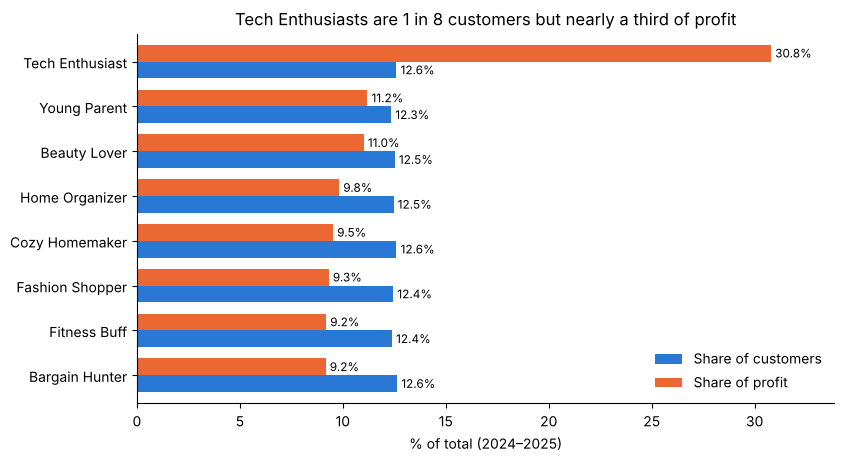

In [ ]:
shares = (segments[["share_of_customers", "share_of_profit"]] * 100).sort_values("share_of_profit")
shares.columns = ["Share of customers", "Share of profit"]

ax = shares.plot.barh(figsize=(9, 4.8), width=0.75, color=["#2a78d6", "#eb6834"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="{:.1f}%", padding=3, fontsize=8.5)
ax.set(title="Tech Enthusiasts are 1 in 8 customers but nearly a third of profit",
       xlabel="% of total (2024–2025)", ylabel="")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
ax.margins(x=0.1)
plt.show()

## 5. Where: Tech Enthusiasts by region and state

In [ ]:
te = cust[cust.customer_segment.eq("Tech Enthusiast")]
stats = dict(customers=("buyer_id", "size"), profit_per_customer=("profit", "mean"), total_profit=("profit", "sum"))
fmt = {"customers": "{:,}", "profit_per_customer": "${:,.0f}", "total_profit": "${:,.0f}",
       "share_of_te_customers": "{:.1%}", "share_of_te_profit": "{:.1%}"}

by_region = te.groupby("region").agg(**stats).sort_values("total_profit", ascending=False).rename_axis("Region")
by_region["share_of_te_customers"] = by_region.customers / len(te)
by_region["share_of_te_profit"] = by_region.total_profit / te.profit.sum()
display(by_region.style.format(fmt))

top_states = (te.groupby(["region", "state"]).agg(**stats)
                .reset_index("region")
                .sort_values("total_profit", ascending=False)
                .rename_axis("State"))
top_states.head(6).style.format(fmt, subset=list(stats))

,customers,profit_per_customer,total_profit,share_of_te_customers,share_of_te_profit
Region,,,,,
West,"2,393",$385,"$921,542",40.0%,38.1%
East,"1,805",$438,"$790,883",30.2%,32.7%
Central,"1,191",$386,"$459,497",19.9%,19.0%
Other,597,$416,"$248,078",10.0%,10.3%


,region,customers,profit_per_customer,total_profit
State,,,,
OR,West,617,$492,"$303,447"
NV,West,610,$400,"$243,861"
CA,West,562,$338,"$190,165"
WA,West,604,$305,"$184,069"
NJ,East,285,$527,"$150,325"
GA,East,284,$510,"$144,777"


## 6. Inputs for the KPI targets

In [ ]:
te_value = te.profit.mean()
electronics = lines[lines.category_name.eq("Electronics")]
can_source = electronics.currently_active_vendor.eq(True) & electronics.active_product.eq(True)
stock = products.groupby(products.category_name.eq("Electronics")).current_stock.mean()

print(f"Two-year profit per Tech Enthusiast: ${te_value:,.0f} -> CAC ceiling at 3:1 = ${te_value / 3:,.0f}")
print(f"Tech Enthusiasts with no orders in 2024–2025: {1 - te.is_active.mean():.1%}")
print(f"Electronics revenue from products that can't currently be sourced: "
      f"{electronics.list_revenue[~can_source].sum() / electronics.list_revenue.sum():.1%}")
print(f"Stock per product: electronics {stock[True]:.0f}, other categories {stock[False]:.0f}")

Two-year profit per Tech Enthusiast: $404 -> CAC ceiling at 3:1 = $135
Tech Enthusiasts with no orders in 2024–2025: 49.7%
Electronics revenue from products that can't currently be sourced: 46.5%
Stock per product: electronics 40, other categories 66


## 7. Conclusion

**Our best customer base is Tech Enthusiasts.** They're 12.6% of customers but 30.8% of profit: \$404 per customer against \$120–150 for every other segment. Their value comes from electronics (87% of their spend, against 20–30% for other segments).

- **Where:** 40% live in the West, led by Oregon (\$303k profit). Customers in the East are worth the most each (\$438), led by New Jersey (\$527) and Georgia (\$510).
- **Risks to growing it:** half of Tech Enthusiasts placed no order in two years, and 46.5% of electronics revenue comes from products the company can't currently source.

### KPIs to acquire more Tech Enthusiasts

| KPI | Target / why |
|---|---|
| Acquisition cost (CAC) by channel | Under about \$135, a third of their \$404 two-year profit |
| New Tech Enthusiasts per month, by region | West for volume, East for value per customer |
| Activation: share placing a first order within 90 days | Half of today's base never orders |
| Electronics in-stock rate | 46.5% of electronics revenue is at supply risk |
| Two-year profit per new customer ÷ CAC | Keep above 3 |

**Limits**
- No marketing spend or acquisition source in the data, so CAC can't be measured yet.
- Profit covers two years, not a full customer lifetime.